## Practical 8 - Pandas and Numpy

In [10]:
import numpy as np
print("Numpy version: ", np.__version__)

Numpy version:  2.5.2


In [25]:
import pandas as pd
print("Pandas version: ", pd.__version__)

Pandas version:  3.0.5


#### `Problem 1: Create a dataframe to display result [Attached as screenshot]`

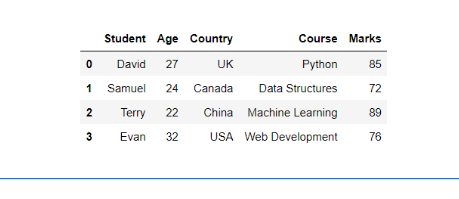

In [12]:
data = {
    "Student" : ["David", "Samuel", "Terry", "Evan"],
    "Age" : [27, 24, 22, 32],
    "Country" : ["UK", "Canada", "China", "USA"],
    "Course" : ["Python", "Data Structure", "Machine Learning", "Web Development"],
    "Marks" : [85, 72, 89, 76]
}

df = pd.DataFrame(data)
print(df)

  Student  Age Country            Course  Marks
0   David   27      UK            Python     85
1  Samuel   24  Canada    Data Structure     72
2   Terry   22   China  Machine Learning     89
3    Evan   32     USA   Web Development     76


#### `Problem 2: Retrieve the Marks column and assign it to a variable b`

In [15]:
b = df['Marks']
print(b)

0    85
1    72
2    89
3    76
Name: Marks, dtype: int64


#### `Problem 3: Retrieve the Country and Course columns and assign it to a variable c`

In [16]:
c = df[['Country', 'Course']]
print(c)

  Country            Course
0      UK            Python
1  Canada    Data Structure
2   China  Machine Learning
3     USA   Web Development


#### `Problem 4: Data Loading & Exploration:` 
1. Create a deatadset containing at least 5 columns(e.g. -> Customer_ID, Name, Age, Gender, Purchase_Amount) and insert 10 records.
2. Load the dataset into a Pandas DataFrame.
3. Display the first 5 rows using head().
4. Get summary statistics using describe().
5. Check for missing values and handle them appropriately. 

In [39]:
# 1. Create a dataset
data = {
    "Customer_ID" : [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Name" : ["Aarav", "Priya", "Rohan", "Sneha", "Vikram", "Ananya", "Rahul", "Isha", "Karan", "Meera"],
    "Age" : [25, 34, 29, 42, 31, 27, 36, 22, 45, 33],
    "Gender" : ["Male", "Female", "Male", "Female", "Male", "Female", "Male", "Female", np.nan, "Female"],
    "Purchase_Amount" : [2500, 4200, 1800, 5600, 3200, 2400, np.nan, 1500, 6100, 3800]
}

# 2. DataFrame
df = pd.DataFrame(data)
print(df)

# 3. Display the first 5 rows
print()
print("First 5 rows: ", end = "\n\n")
print(df.head())

# 4. Display summary statistics 
print("\nSummary Statistics: ", end = "\n\n")
print(df.describe())

# 5. Check for missing values 
print("\nMissing Values: ", end = "\n\n")
print(df.isnull().sum())

# Handle missing values 
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Purchase_Amount'] = df['Purchase_Amount'].fillna(df['Purchase_Amount'].median())

# Check missing values again
print("\nMissing Values After Handling: ", end = "\n\n")
print(df.isnull().sum())

   Customer_ID    Name  Age  Gender  Purchase_Amount
0          101   Aarav   25    Male           2500.0
1          102   Priya   34  Female           4200.0
2          103   Rohan   29    Male           1800.0
3          104   Sneha   42  Female           5600.0
4          105  Vikram   31    Male           3200.0
5          106  Ananya   27  Female           2400.0
6          107   Rahul   36    Male              NaN
7          108    Isha   22  Female           1500.0
8          109   Karan   45     NaN           6100.0
9          110   Meera   33  Female           3800.0

First 5 rows: 

   Customer_ID    Name  Age  Gender  Purchase_Amount
0          101   Aarav   25    Male           2500.0
1          102   Priya   34  Female           4200.0
2          103   Rohan   29    Male           1800.0
3          104   Sneha   42  Female           5600.0
4          105  Vikram   31    Male           3200.0

Summary Statistics: 

       Customer_ID        Age  Purchase_Amount
count     10

#### `Problem 5: Data Filtering & Selection:`
1. Retrieve all customers whose age is greater than 30.
2. Find the total Purchase Amount for male and female customers separately.
3. Select only the Customer_ID, Name and Purchase_Amount columns.

In [40]:
# 1. Retrieve customers whose age is greater than 30
print("Customers Older Than 30: ", end = "\n\n")
print(df[df['Age'] > 30])

# 2. Calculate total purchase amount by gender
print("\nTotal Purchase Amount by Gender: ", end = "\n\n")
print(df.groupby('Gender')['Purchase_Amount'].sum())

# 3. Select specific columns 
print("\nSelected Columns: ", end = "\n\n")
print(df[['Customer_ID', 'Name', 'Purchase_Amount']])

Customers Older Than 30: 

   Customer_ID    Name  Age  Gender  Purchase_Amount
1          102   Priya   34  Female           4200.0
3          104   Sneha   42  Female           5600.0
4          105  Vikram   31    Male           3200.0
6          107   Rahul   36    Male           3200.0
8          109   Karan   45  Female           6100.0
9          110   Meera   33  Female           3800.0

Total Purchase Amount by Gender: 

Gender
Female    23600.0
Male      10700.0
Name: Purchase_Amount, dtype: float64

Selected Columns: 

   Customer_ID    Name  Purchase_Amount
0          101   Aarav           2500.0
1          102   Priya           4200.0
2          103   Rohan           1800.0
3          104   Sneha           5600.0
4          105  Vikram           3200.0
5          106  Ananya           2400.0
6          107   Rahul           3200.0
7          108    Isha           1500.0
8          109   Karan           6100.0
9          110   Meera           3800.0


#### `Problem 6: Data Transformation and Aggregation:`
1. Add a new column "Discounted_Price", where each customer gets a 10% discount on their Purchase_Amount.
2. Group the data by Gender and calculate the average Purchase_Amount.
3. Sort the dataset by purchase_amount in descending order.

In [50]:
# 1. Add a new column with a 10% discount 
df['Discounted_Price'] = df['Purchase_Amount'] * 0.90
print("After Discounted_Price Added: ", end = "\n\n")
print(df, end = "\n\n")

# 2. Calcuate average purchase amount by gender
print("Average Purchase Amount by Gender: ", end = "\n")
print(df.groupby('Gender')['Purchase_Amount'].mean())

# 3. sort by purchase amount in descending order 
df = df.sort_values(by = 'Purchase_Amount', ascending = False)

print("\nSorted Dataset: ", end = "\n\n")
print(df)

After Discounted_Price Added: 

   Customer_ID    Name  Age  Gender  Purchase_Amount  Discounted_Price
8          109   Karan   45  Female           6100.0            5490.0
3          104   Sneha   42  Female           5600.0            5040.0
1          102   Priya   34  Female           4200.0            3780.0
9          110   Meera   33  Female           3800.0            3420.0
6          107   Rahul   36    Male           3200.0            2880.0
4          105  Vikram   31    Male           3200.0            2880.0
0          101   Aarav   25    Male           2500.0            2250.0
5          106  Ananya   27  Female           2400.0            2160.0
2          103   Rohan   29    Male           1800.0            1620.0
7          108    Isha   22  Female           1500.0            1350.0

Average Purchase Amount by Gender: 
Gender
Female    3933.333333
Male      2675.000000
Name: Purchase_Amount, dtype: float64

Sorted Dataset: 

   Customer_ID    Name  Age  Gender  Purch